<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 4 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Réalisez une étude de santé publique avec R ou Python
</h2>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner codes, textes et graphique.

Cet outil est formidable pour plusieurs raisons:

+ il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'un instruction, de la corriger si nécessaire.
+ De rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ d'agrémenter de graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandée.

Et garder à l'esprit, qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



Note jeremy 
Est ce qu'il faut faire le calcul de la sous nutrition sur les pays qu'on a ? 
Est ce qu'il faut faire des graphiques ?
Rajouter le soja
La liste des céréales est difficile a trouver ...

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
#Importation de la librairie Pandas
import pandas as pd

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Chargement des fichiers Excel</h3>
</div>

In [2]:
#Importation du fichier population.csv
population = pd.read_csv('DAN-P4-FAO/population.csv')

#Importation du fichier dispo_alimentaire.csv
dispo_alimentaire = pd.read_csv('DAN-P4-FAO/dispo_alimentaire.csv')


#Importation du fichier aide_alimentaire.csv
aide_alimentaire = pd.read_csv('DAN-P4-FAO/aide_alimentaire.csv')


#Importation du fichier sous_nutrition.csv
sous_nutrition = pd.read_csv('DAN-P4-FAO/sous_nutrition.csv')


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Analyse exploratoire du fichier population</h3>
</div>

In [3]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s).".format(population.shape[0]))
print("Le tableau comporte {} colonne(s)".format(population.shape[1]))

Le tableau comporte 1416 observation(s) ou article(s).
Le tableau comporte 3 colonne(s)


In [4]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes

In [5]:
#Affichage les 5 premières lignes de la table with Pandas
population.head()

,Zone,Année,Valeur
0,Afghanistan,2013,32269.589
1,Afghanistan,2014,33370.794
2,Afghanistan,2015,34413.603
3,Afghanistan,2016,35383.032
4,Afghanistan,2017,36296.113


In [6]:
#Nous allons harmoniser les unités. Pour cela, nous avons décidé de multiplier la population par 1000
#Multiplication de la colonne valeur par 1000
population['Valeur']=population.Valeur.multiply(1000)

In [7]:
#changement du nom de la colonne Valeur par Population
population = population.rename(columns={'Valeur': 'Population'})

In [8]:
#Affichage les 5 premières lignes de la table pour voir les modifications
#population.head()
display(population)

,Zone,Année,Population
0,Afghanistan,2013,32269589.0
1,Afghanistan,2014,33370794.0
2,Afghanistan,2015,34413603.0
3,Afghanistan,2016,35383032.0
4,Afghanistan,2017,36296113.0
...,...,...,...
1411,Zimbabwe,2014,13586707.0
1412,Zimbabwe,2015,13814629.0
1413,Zimbabwe,2016,14030331.0
1414,Zimbabwe,2017,14236595.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Analyse exploratoire du fichier disponibilité alimentaire</h3>
</div>

In [9]:
#Afficher les dimensions du dataset
dispo_alimentaire.shape


(15605, 18)

In [10]:
#Consulter le nombre de colonnes
display(str(dispo_alimentaire.shape[1])+ " colonnes")
dispo_alimentaire.dtypes

'18 colonnes'

Zone                                                              object
Produit                                                           object
Origine                                                           object
Aliments pour animaux                                            float64
Autres Utilisations                                              float64
Disponibilité alimentaire (Kcal/personne/jour)                   float64
Disponibilité alimentaire en quantité (kg/personne/an)           float64
Disponibilité de matière grasse en quantité (g/personne/jour)    float64
Disponibilité de protéines en quantité (g/personne/jour)         float64
Disponibilité intérieure                                         float64
Exportations - Quantité                                          float64
Importations - Quantité                                          float64
Nourriture                                                       float64
Pertes                                             

In [11]:
#Affichage les 5 premières lignes de la table
dispo_alimentaire.head(5)

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53.0,NaN,NaN,53.0,NaN,53.0,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41.0,2.0,40.0,39.0,2.0,3.0,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82.0,NaN,82.0,82.0,NaN,NaN,NaN,NaN,NaN


In [12]:
#remplacement des NaN dans le dataset par des 0

#Utilisation d'un masque pour 1 colonne / serie
serie1 = dispo_alimentaire["Exportations - Quantité"]
#serie1
#serie1.isna()
mask1 = serie1.isna()
dispo_alimentaire.loc[mask1, "Exportations - Quantité"] = 0
dispo_alimentaire.head()


#utilsation de fillna pour l'entièreté
dispo_alimentaire = dispo_alimentaire.fillna(0)

In [13]:
#Test de groupby mean()
dispo_alimentaire.groupby(['Zone', 'Produit'])['Disponibilité alimentaire en quantité (kg/personne/an)'].sum()


Zone          Produit              
Afghanistan   Abats Comestible         1.72
              Agrumes, Autres          1.29
              Aliments pour enfants    0.06
              Ananas                   0.00
              Bananes                  2.70
                                       ... 
Îles Salomon  Viande de Suides         4.70
              Viande de Volailles      3.34
              Viande, Autre            0.06
              Vin                      0.07
              Épices, Autres           0.48
Name: Disponibilité alimentaire en quantité (kg/personne/an), Length: 15605, dtype: float64

In [14]:
#Nombres de zones
display(dispo_alimentaire['Zone'].unique().size)


174

In [15]:
#multiplication de toutes les lignes contenant des milliers de tonnes en Kg

#noms des colonnes 
col_Ktonnes = list(dispo_alimentaire.columns[3:5])
col_Ktonnes += list(dispo_alimentaire.columns[9:18])
display(col_Ktonnes)
len(col_Ktonnes)

#filtre sur ces colonnes

#Run Once
dispo_alimentaire[col_Ktonnes] *= 1000

#Check
#dispo_alimentaire[col_Ktonnes]


['Aliments pour animaux',
 'Autres Utilisations',
 'Disponibilité intérieure',
 'Exportations - Quantité',
 'Importations - Quantité',
 'Nourriture',
 'Pertes',
 'Production',
 'Semences',
 'Traitement',
 'Variation de stock']

In [16]:
#Affichage les 5 premières lignes de la table
dispo_alimentaire.head()

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,0.0,0.0,5.0,1.72,0.20,0.77,53000.0,0.0,0.0,53000.0,0.0,53000.0,0.0,0.0,0.0
1,Afghanistan,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,0.02,41000.0,2000.0,40000.0,39000.0,2000.0,3000.0,0.0,0.0,0.0
2,Afghanistan,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,0.03,2000.0,0.0,2000.0,2000.0,0.0,0.0,0.0,0.0,0.0
3,Afghanistan,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Afghanistan,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,0.05,82000.0,0.0,82000.0,82000.0,0.0,0.0,0.0,0.0,0.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier aide alimentaire</h3>
</div>

In [17]:
#Afficher les dimensions du dataset
aide_alimentaire.shape

(1475, 4)

In [18]:
#Consulter le nombre de colonnes
aide_alimentaire.shape[1]

4

In [19]:
#Affichage les 5 premières lignes de la table
aide_alimentaire.head()

,Pays bénéficiaire,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224
3,Afghanistan,2014,Blé et Farin,15160
4,Afghanistan,2013,Céréales,40504


In [20]:
#changement du nom de la colonne Pays bénéficiaire par Zone
aide_alimentaire.rename(columns={"Pays bénéficiaire": "Zone"})

,Zone,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224
3,Afghanistan,2014,Blé et Farin,15160
4,Afghanistan,2013,Céréales,40504
...,...,...,...,...
1470,Zimbabwe,2015,Mélanges et préparations,96
1471,Zimbabwe,2013,Non-céréales,5022
1472,Zimbabwe,2014,Non-céréales,2310
1473,Zimbabwe,2015,Non-céréales,306


In [21]:
#Multiplication de la colonne Aide_alimentaire qui contient des tonnes par 1000 pour avoir des kg
aide_alimentaire["Valeur"] *= 1000

In [22]:
#Affichage les 5 premières lignes de la table
aide_alimentaire.head()

,Pays bénéficiaire,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682000
1,Afghanistan,2014,Autres non-céréales,335000
2,Afghanistan,2013,Blé et Farin,39224000
3,Afghanistan,2014,Blé et Farin,15160000
4,Afghanistan,2013,Céréales,40504000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier sous nutrition</h3>
</div>

In [23]:
#Afficher les dimensions du dataset
sous_nutrition.shape

(1218, 3)

In [24]:
#Consulter le nombre de colonnes
sous_nutrition.shape[1]

3

In [25]:
#Afficher les 5 premières lignes de la table
sous_nutrition.head()

,Zone,Année,Valeur
0,Afghanistan,2012-2014,8.6
1,Afghanistan,2013-2015,8.8
2,Afghanistan,2014-2016,8.9
3,Afghanistan,2015-2017,9.7
4,Afghanistan,2016-2018,10.5


In [26]:
#Conversion de la colonne sous nutrition en numérique
sous_nutrition.dtypes
sous_nutrition[sous_nutrition['Valeur'] == "<0.1"]
#sous_nutrition['Valeur'] = pd.to_numeric(sous_nutrition['Valeur'])

,Zone,Année,Valeur
60,Arménie,2012-2014,<0.1
61,Arménie,2013-2015,<0.1
62,Arménie,2014-2016,<0.1
63,Arménie,2015-2017,<0.1
64,Arménie,2016-2018,<0.1
...,...,...,...
1183,Vanuatu,2013-2015,<0.1
1184,Vanuatu,2014-2016,<0.1
1185,Vanuatu,2015-2017,<0.1
1186,Vanuatu,2016-2018,<0.1


In [27]:
#Conversion de la colonne (avec l'argument errors=coerce qui permet de convertir automatiquement les lignes qui ne sont pas des nombres en NaN)
#Puis remplacement des NaN en 0
sous_nutrition['Valeur'] = pd.to_numeric(sous_nutrition['Valeur'], errors="coerce")
sous_nutrition = sous_nutrition.fillna(0)

In [28]:
#changement du nom de la colonne Valeur par sous_nutrition
sous_nutrition.rename(columns = {'Valeur': 'sous_nutrition'}, inplace= "True" )

In [29]:
#Multiplication de la colonne sous_nutrition par 1000000
sous_nutrition["sous_nutrition"] *= 1000000

In [30]:
#Afficher les 5 premières lignes de la table
sous_nutrition.head()

,Zone,Année,sous_nutrition
0,Afghanistan,2012-2014,8600000.0
1,Afghanistan,2013-2015,8800000.0
2,Afghanistan,2014-2016,8900000.0
3,Afghanistan,2015-2017,9700000.0
4,Afghanistan,2016-2018,10500000.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.1 - Proportion de personnes en sous nutrition</h3>
</div>

In [31]:
# Il faut tout d'abord faire une jointure entre la table population et la table sous nutrition, en ciblant l'année 2017
population[population["Année"] == 2017]

# different values of Année in sous_nutrition
#sous_nutrition.groupby("Année")["sous_nutrition"].mean()

# sous_nutrition 2015-2017 | 2017-2019
sous_nutrition[(sous_nutrition["Année"] == "2015-2017") | (sous_nutrition["Année"] == "2017-2019")]

# sous_nutrition 2015-2017 | 2017-2019 -> Moyenne lorsque double représentation
sous_nut_2017 = sous_nutrition[(sous_nutrition["Année"] == "2015-2017") | (sous_nutrition["Année"] == "2017-2019")].groupby("Zone")["sous_nutrition"].mean()
#display(sous_nut_2017)


Pop_SsNut_2017 = population[population["Année"] == 2017].merge(sous_nut_2017, on = "Zone")

In [32]:
#Affichage du dataset
Pop_SsNut_2017.sort_values(by = "sous_nutrition", ascending = False)

,Zone,Année,Population,sous_nutrition
84,Inde,2017,1.338677e+09,190050000.0
136,Pakistan,2017,2.079062e+08,25350000.0
85,Indonésie,2017,2.646510e+08,24050000.0
128,Nigéria,2017,1.908732e+08,23400000.0
16,Bangladesh,2017,1.596854e+08,21600000.0
...,...,...,...,...
196,Uruguay,2017,3.436641e+06,0.0
197,Vanuatu,2017,2.855100e+05,0.0
200,Yémen,2017,2.783482e+07,0.0
201,Zambie,2017,1.685360e+07,0.0


In [33]:
#Calcul et affichage du nombre de personnes en état de sous nutrition

print("Nombre total de personnes en sous nutrition en 20217")
total_SNut_2017 = Pop_SsNut_2017["sous_nutrition"].sum()
print(f"{total_SNut_2017:,.2f}")

print("Nombre total de personnes dans les données")
#print(Pop_SsNut_2017["Population"].sum())
print(f"{Pop_SsNut_2017["Population"].sum():,.2f}")

print("Proportion de personnes en sous-nutrition")
print("{:.2%}".format(Pop_SsNut_2017["sous_nutrition"].sum() / Pop_SsNut_2017["Population"].sum()))

Nombre total de personnes en sous nutrition en 20217
536,400,000.00
Nombre total de personnes dans les données
7,543,798,779.00
Proportion de personnes en sous-nutrition
7.11%


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.2 - Nombre théorique de personne qui pourrait être nourries</h3>
</div>

In [34]:
#Combien mange en moyenne un être humain ? Source => 

#En moyenne mondiale, un être humain adulte consomme ou dispose d'environ 1 065 800 kcal par an (basé sur la moyenne mondiale de disponibilité alimentaire de la FAO (Organisation des Nations unies pour l'alimentation et l'agriculture)).

dispoAnnMoyKcal = 1065800
#print(dispoAnnMoyKcal)

In [35]:
#exploration: somme de dispo alimentaire directement dans le tableau dispo alimentaire (sans jointure)
print("-- Totaux monde par personne par an --")
print(f"{dispo_alimentaire["Disponibilité alimentaire (Kcal/personne/jour)"].sum():,.0f}"+" kcal")
print(f"{dispo_alimentaire["Disponibilité alimentaire en quantité (kg/personne/an)"].sum():,.0f}"+" kg")
# n'a pas de sens d'additionner des chiffres "par personne"

print("\n-- Totaux par pays par personne par an --")
display(pd.concat([dispo_alimentaire.groupby("Zone")["Disponibilité alimentaire (Kcal/personne/jour)"].sum(), dispo_alimentaire.groupby("Zone")["Disponibilité alimentaire en quantité (kg/personne/an)"].sum()], axis=1))

print("\n-- Totaux par pays par origine par an --")
pd.concat([dispo_alimentaire.groupby("Origine")["Disponibilité alimentaire (Kcal/personne/jour)"].sum(), dispo_alimentaire.groupby("Origine")["Disponibilité alimentaire en quantité (kg/personne/an)"].sum()], axis=1)

print("\n-- Totaux par pays par origine par an --")
dispo_alimentaire.groupby("Origine")[["Disponibilité alimentaire (Kcal/personne/jour)","Disponibilité alimentaire en quantité (kg/personne/an)"]].sum()



-- Totaux monde par personne par an --
495,442 kcal
122,202 kg

-- Totaux par pays par personne par an --


,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an)
Zone,,
Afghanistan,2087.0,351.41
Afrique du Sud,3020.0,564.80
Albanie,3188.0,1095.54
Algérie,3293.0,809.13
Allemagne,3503.0,957.52
...,...,...
Émirats arabes unis,3275.0,700.24
Équateur,2346.0,544.91
États-Unis d'Amérique,3682.0,1002.39



-- Totaux par pays par origine par an --

-- Totaux par pays par origine par an --


,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an)
Origine,,
animale,96660.0,34491.46
vegetale,398782.0,87710.48


In [36]:
#visualisation de la distribution des Disposiblités par pays
dispo_by_ctry = pd.DataFrame(dispo_alimentaire.groupby("Zone")["Disponibilité alimentaire (Kcal/personne/jour)"].sum())
#dispo_by_ctry.reset_index()
dispo_by_ctry.sort_values("Disponibilité alimentaire (Kcal/personne/jour)", ascending = False, inplace = True)

dispo_by_ctry.head()
dispo_by_ctry.tail()

,Disponibilité alimentaire (Kcal/personne/jour)
Zone,
Haïti,2089.0
Afghanistan,2087.0
Madagascar,2056.0
Zambie,1924.0
République centrafricaine,1879.0


array([[<Axes: title={'center': 'Disponibilité alimentaire (Kcal/personne/jour)'}>]],
      dtype=object)

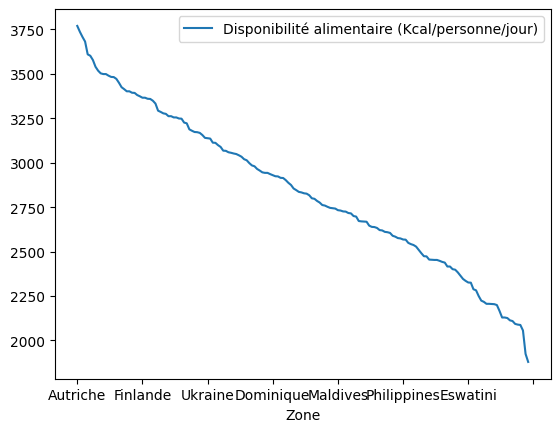

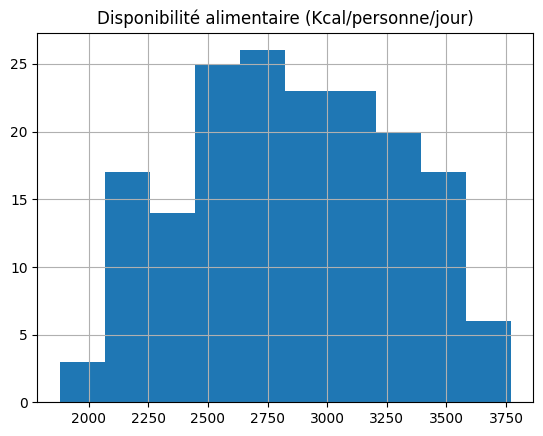

In [37]:
dispo_by_ctry.plot()
dispo_by_ctry.hist()


In [38]:
#On commence par faire une jointure entre le data frame population et Dispo_alimentaire afin d'ajouter dans ce dernier la population

#choix de population en 2017
dispo_alim_nb_habitants = pd.merge(dispo_alimentaire, population[population["Année"] == 2017], on="Zone")


In [39]:
#Affichage du nouveau dataframe
display(dispo_alim_nb_habitants)

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock,Année,Population
0,Afghanistan,Abats Comestible,animale,0.0,0.0,5.0,1.72,0.20,0.77,53000.0,0.0,0.0,53000.0,0.0,53000.0,0.0,0.0,0.0,2017,36296113.0
1,Afghanistan,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,0.02,41000.0,2000.0,40000.0,39000.0,2000.0,3000.0,0.0,0.0,0.0,2017,36296113.0
2,Afghanistan,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,0.03,2000.0,0.0,2000.0,2000.0,0.0,0.0,0.0,0.0,0.0,2017,36296113.0
3,Afghanistan,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2017,36296113.0
4,Afghanistan,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,0.05,82000.0,0.0,82000.0,82000.0,0.0,0.0,0.0,0.0,0.0,2017,36296113.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15411,Îles Salomon,Viande de Suides,animale,0.0,0.0,45.0,4.70,4.28,1.41,3000.0,0.0,0.0,3000.0,0.0,2000.0,0.0,0.0,0.0,2017,636039.0
15412,Îles Salomon,Viande de Volailles,animale,0.0,0.0,11.0,3.34,0.69,1.14,2000.0,0.0,2000.0,2000.0,0.0,0.0,0.0,0.0,0.0,2017,636039.0
15413,Îles Salomon,"Viande, Autre",animale,0.0,0.0,0.0,0.06,0.00,0.04,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2017,636039.0
15414,Îles Salomon,Vin,vegetale,0.0,0.0,0.0,0.07,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2017,636039.0


In [40]:
#Création de la colonne dispo_kcal avec calcul des kcal disponibles mondialement
dispo_alim_nb_habitants["dispo_kcal"] = dispo_alim_nb_habitants["Disponibilité alimentaire (Kcal/personne/jour)"]*dispo_alim_nb_habitants["Population"]*365

#display(dispo_alim_nb_habitants[["Zone", "Produit", "dispo_kcal"]])


In [41]:
#Calcul du nombre d'humains pouvant être nourris

print("Total des kcal disponibles")
print(f"{dispo_alim_nb_habitants["dispo_kcal"].sum():,.0f}"+" kcal\n")

print("Nombre de personnes nourries sur la base d'un besoin de \"disponibilité\" de " + f"{dispoAnnMoyKcal:,.0f}" + " kcal par personne par an")
print(f"{dispo_alim_nb_habitants["dispo_kcal"].sum() / dispoAnnMoyKcal :,.0f}"+" personnes\n")


Total des kcal disponibles
7,635,429,388,975,815 kcal

Nombre de personnes nourries sur la base d'un besoin de "disponibilité" de 1,065,800 kcal par personne par an
7,164,035,831 personnes



<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.3 - Nombre théorique de personne qui pourrait être nourrie avec les produits végétaux</h3>
</div>

In [42]:
#Transfert des données avec les végétaux dans un nouveau dataframe
dispo_alim_nb_habitants_Vege = dispo_alim_nb_habitants.loc[dispo_alim_nb_habitants["Origine"] == "vegetale"]

dispo_alim_nb_habitants_Vege.shape

(11751, 21)

In [43]:
#Calcul du nombre de kcal disponible pour les végétaux
print("Total des kcal végétales disponibles")
print(f"{dispo_alim_nb_habitants_Vege["dispo_kcal"].sum():,.0f}"+" kcal\n")


Total des kcal végétales disponibles
6,300,178,937,197,865 kcal



In [44]:
#Calcul du nombre d'humains pouvant être nourris avec les végétaux
print("Total des kcal Végétales disponibles")
print(f"{dispo_alim_nb_habitants_Vege["dispo_kcal"].sum():,.0f}"+" kcal\n")

print("Nombre de personnes nourries par le Végétal sur la base d'un besoin de \"disponibilité\" de " + f"{dispoAnnMoyKcal:,.0f}" + " kcal par personne par an")
print(f"{dispo_alim_nb_habitants_Vege["dispo_kcal"].sum() / dispoAnnMoyKcal :,.0f}"+" personnes\n")

Total des kcal Végétales disponibles
6,300,178,937,197,865 kcal

Nombre de personnes nourries par le Végétal sur la base d'un besoin de "disponibilité" de 1,065,800 kcal par personne par an
5,911,220,620 personnes



<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.4 - Utilisation de la disponibilité intérieure</h3>
</div>

In [45]:
#Calcul de la disponibilité totale
print("Total monde de l'alimentation disponible par an")
#dispo_alimentaire["Disponibilité intérieure"].sum()
print(f"{dispo_alimentaire["Disponibilité intérieure"].sum():,.0f}"+" milliers de tonnes")


Total monde de l'alimentation disponible par an
9,848,994,000 milliers de tonnes


In [46]:
# Total de la dispo par pays 
pd.DataFrame(dispo_alimentaire.groupby("Zone")["Disponibilité intérieure"].sum()).sort_values("Disponibilité intérieure", ascending = False)

,Disponibilité intérieure
Zone,
"Chine, continentale",2.036726e+09
Inde,1.100838e+09
Brésil,1.033314e+09
États-Unis d'Amérique,7.779920e+08
Fédération de Russie,2.637840e+08
...,...
Sainte-Lucie,1.360000e+05
Grenade,9.600000e+04
Antigua-et-Barbuda,7.900000e+04


In [47]:
#création d'une boucle for pour afficher les différentes valeurs en fonction des colonnes aliments pour animaux, pertes, nourritures, 

# Liste des colonnes
#display(dispo_alimentaire.loc[0])
#display(dispo_alimentaire.columns)
#dispoIntCols = ["Aliments pour animaux", "Pertes", "Nourriture"]
dispoIntCols = dispo_alimentaire.columns[[3, 12, 13]]
display(dispoIntCols)

for col in dispoIntCols:
    print(col + ": " + f"{dispo_alimentaire[col].sum():,.0f}"+" milliers de tonnes")
    #display(dispo_alimentaire[col])


Index(['Aliments pour animaux', 'Nourriture', 'Pertes'], dtype='object')

Aliments pour animaux: 1,304,245,000 milliers de tonnes
Nourriture: 4,876,258,000 milliers de tonnes
Pertes: 453,698,000 milliers de tonnes


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.5 - Utilisation des céréales</h3>
</div>

In [147]:
#Création d'une liste avec toutes les variables
dispoAlimList = dispo_alimentaire.columns.tolist()
print(dispoAlimList)
#produits = dispo_alimentaire.loc[dispo_alimentaire["Origine"] == "vegetale"].groupby("Produit")["Produit"].count().to_frame()
#produits = dispo_alimentaire.loc[dispo_alimentaire["Origine"] == "vegetale"].groupby("Produit", as_index=False)["Produit"].min()
produits = dispo_alimentaire.loc[dispo_alimentaire["Origine"] == "vegetale"]["Produit"].unique()
produits.sort()
display(produits)
#print(produits.index.tolist())


['Zone', 'Produit', 'Origine', 'Aliments pour animaux', 'Autres Utilisations', 'Disponibilité alimentaire (Kcal/personne/jour)', 'Disponibilité alimentaire en quantité (kg/personne/an)', 'Disponibilité de matière grasse en quantité (g/personne/jour)', 'Disponibilité de protéines en quantité (g/personne/jour)', 'Disponibilité intérieure', 'Exportations - Quantité', 'Importations - Quantité', 'Nourriture', 'Pertes', 'Production', 'Semences', 'Traitement', 'Variation de stock']


array(['Agrumes, Autres', 'Alcool, non Comestible',
       'Aliments pour enfants', 'Ananas', 'Arachides Decortiquees',
       'Avoine', 'Bananes', 'Bananes plantains', 'Bière', 'Blé',
       'Boissons Alcooliques', 'Boissons Fermentés', 'Café',
       'Citrons & Limes', 'Coco (Incl Coprah)', 'Céréales, Autres',
       'Dattes', 'Edulcorants Autres', 'Feve de Cacao', 'Fruits, Autres',
       'Girofles', 'Graines Colza/Moutarde', 'Graines de coton',
       'Graines de tournesol', 'Haricots', 'Huil Plantes Oleif Autr',
       'Huile Graines de Coton', "Huile d'Arachide", "Huile d'Olive",
       'Huile de Coco', 'Huile de Colza&Moutarde',
       'Huile de Germe de Maïs', 'Huile de Palme', 'Huile de Palmistes',
       'Huile de Soja', 'Huile de Son de Riz', 'Huile de Sésame',
       'Huile de Tournesol', 'Ignames', 'Légumes, Autres',
       'Légumineuses Autres', 'Manioc', 'Maïs', 'Miel', 'Millet',
       'Miscellanees', 'Noix', 'Oignons', 'Olives', 'Oranges, Mandarines',
       'Orge', 'P

In [149]:
#Création d'un dataframe avec les informations uniquement pour ces céréales
cerealesRef = ["Avoine", "Blé", "Céréales, Autres", "Maïs", "Millet", "Orge", "Seigle"]

#vérification que les données tapées manuellemet sont bien celles du fichier en les re extrayant
cerealesRefDF = pd.DataFrame(cerealesRef, columns=["Produit"])
#display(cerealesRefDF)
produitsDF = pd.DataFrame(produits, columns=["Produit"])
#display(produitsDF)
produitsValides = pd.merge(cerealesRefDF, produitsDF, how="inner", on="Produit" )
display(produitsValides)

cerealesRefChecked = produitsValides["Produit"].to_list()
display(cerealesRefChecked) 


,Produit
0,Avoine
1,Blé
2,"Céréales, Autres"
3,Maïs
4,Millet
5,Orge
6,Seigle


['Avoine', 'Blé', 'Céréales, Autres', 'Maïs', 'Millet', 'Orge', 'Seigle']

In [180]:
#Affichage de la proportion d'alimentation animale

#Proportion d'alimentation animale en général
display(dispo_alimentaire.groupby("Origine")["Disponibilité alimentaire en quantité (kg/personne/an)"].sum())

totalDaAnimale = dispo_alimentaire.loc[dispo_alimentaire["Origine"] == "animale"]["Disponibilité alimentaire (Kcal/personne/jour)"].sum()
totalDa = dispo_alimentaire["Disponibilité alimentaire (Kcal/personne/jour)"].sum()
print("Proportion d'alimentation animale en général")
print(f"{totalDaAnimale/totalDa :.1%}")

OriginePieLabels = dispo_alimentaire.groupby("Origine", as_index=False)["Disponibilité alimentaire en quantité (kg/personne/an)"].sum()["Origine"]
display(OriginePieLabels)

OriginePieSizes = dispo_alimentaire.groupby("Origine", as_index=False)["Disponibilité alimentaire en quantité (kg/personne/an)"].sum()["Disponibilité alimentaire en quantité (kg/personne/an)"]
display(OriginePieSizes)

Origine
animale     34491.46
vegetale    87710.48
Name: Disponibilité alimentaire en quantité (kg/personne/an), dtype: float64

Proportion d'alimentation animale en général
19.5%


0     animale
1    vegetale
Name: Origine, dtype: object

0    34491.46
1    87710.48
Name: Disponibilité alimentaire en quantité (kg/personne/an), dtype: float64

([<matplotlib.patches.Wedge at 0x119a705f0>,
 [Text(0.6951585595000606, 0.8524990188579697, 'animale'),
  Text(-0.6951584341593176, -0.8524991210653334, 'vegetale')])

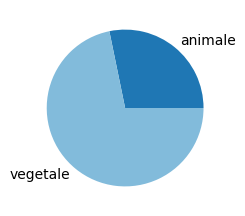

In [181]:
#Affichage de la proportion d'alimentation animale
import matplotlib.pyplot as plt

plt.style.use('_mpl-gallery-nogrid')

fig, ax = plt.subplots()
ax.pie(OriginePieSizes, labels=OriginePieLabels)



<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.6 - Pays avec la proportion de personnes sous-alimentée la plus forte en 2017</h3>
</div>

In [ ]:
#Création de la colonne proportion par pays
display(sous_nutrition)

# Liste des pays avec des valeurs vides (suite au constat que Zimbabwe est à zeroo)
#display(
Sous_nut_Min_Max = pd.merge(
sous_nutrition.groupby("Zone", as_index=False)["sous_nutrition"].min(),
sous_nutrition.groupby("Zone", as_index=False)["sous_nutrition"].max(),
on="Zone"
)
Sous_nut_Min_Max.loc[Sous_nut_Min_Max["sous_nutrition_x"] == 0][["Zone", "sous_nutrition_y"]].sort_values(by="sous_nutrition_y", ascending=False)

print("Il existe des pays avec des valeurs nulles dans certaines années")
print("Methode : conserver d'abord toutes les valeurs non nulles, avant de faire des moyennes par pays")

#sous_nutrition["sous_nutrition"].isna().sort_values()

sous_nut_silver = pd.DataFrame(sous_nutrition.loc[sous_nutrition["sous_nutrition"] > 0 ])
display(sous_nut_silver)
print("shape full" + str(sous_nutrition.shape))
print("shape filtré" + str(sous_nut_silver.shape))

,Zone,Année,sous_nutrition
0,Afghanistan,2012-2014,8600000.0
1,Afghanistan,2013-2015,8800000.0
2,Afghanistan,2014-2016,8900000.0
3,Afghanistan,2015-2017,9700000.0
4,Afghanistan,2016-2018,10500000.0
...,...,...,...
1213,Zimbabwe,2013-2015,0.0
1214,Zimbabwe,2014-2016,0.0
1215,Zimbabwe,2015-2017,0.0
1216,Zimbabwe,2016-2018,0.0


Il existe des pays avec des valeurs nulles dans certaines années
Methode : conserver d'abord toutes les valeurs non nulles, avant de faire des moyennes par pays


,Zone,Année,sous_nutrition
0,Afghanistan,2012-2014,8600000.0
1,Afghanistan,2013-2015,8800000.0
2,Afghanistan,2014-2016,8900000.0
3,Afghanistan,2015-2017,9700000.0
4,Afghanistan,2016-2018,10500000.0
...,...,...,...
1195,Viet Nam,2013-2015,8300000.0
1196,Viet Nam,2014-2016,7600000.0
1197,Viet Nam,2015-2017,7100000.0
1198,Viet Nam,2016-2018,6500000.0


shape full(1218, 3)
shape filtré(504, 3)


,Zone,Année,sous_nutrition
24,Allemagne,2012-2014,0.0
25,Allemagne,2013-2015,0.0
26,Allemagne,2014-2016,0.0
27,Allemagne,2015-2017,0.0
28,Allemagne,2016-2018,0.0
...,...,...,...
1213,Zimbabwe,2013-2015,0.0
1214,Zimbabwe,2014-2016,0.0
1215,Zimbabwe,2015-2017,0.0
1216,Zimbabwe,2016-2018,0.0


In [ ]:
# jointure avec la population, sur les lignes non nulles
Range_Années = sous_nut_silver["Année"].unique()

# Cas 2012-2014
#sous_nut_silver.loc[sous_nut_silver["Année"] == "2012-2014", "Année"]
#sous_nut_silver.loc[sous_nut_silver["Année"] == "2012-2014", "Année"] = "2013"

# Cas général
Années = list(range(2013, 2019))
print(Années)

replace_années = pd.DataFrame({"Range":Range_Années, "Année":Années})
display(replace_années)

for a in range(0,len(replace_années)) :
    #print(a)
    sous_nut_silver.loc[sous_nut_silver["Année"] == replace_années.iat[a, 0], "Année"] = replace_années.iat[a, 1]
    print(str(replace_années.iat[a, 0]) + " -> " + str(replace_années.iat[a, 1]))
    #print(b)



[2013, 2014, 2015, 2016, 2017, 2018]


,Range,Année
0,2013,2013
1,2014,2014
2,2015,2015
3,2016,2016
4,2017,2017
5,2018,2018


2013 -> 2013
2014 -> 2014
2015 -> 2015
2016 -> 2016
2017 -> 2017
2018 -> 2018


,Zone,Année,sous_nutrition,Population
0,Afghanistan,2013,8600000.0,32269589.0
1,Afghanistan,2014,8800000.0,33370794.0
2,Afghanistan,2015,8900000.0,34413603.0
3,Afghanistan,2016,9700000.0,35383032.0
4,Afghanistan,2017,10500000.0,36296113.0
...,...,...,...,...
499,Viet Nam,2014,8300000.0,91713848.0
500,Viet Nam,2015,7600000.0,92677076.0
501,Viet Nam,2016,7100000.0,93640422.0
502,Viet Nam,2017,6500000.0,94600648.0


In [312]:
# Pourcentage de sous nutrition

# jointure avec la population, sur les lignes non nulles
sous_nutrition_x_pop = pd.merge(sous_nut_silver, population, on=["Zone","Année"])
display(sous_nutrition_x_pop)

# calcul % sur chaque ligne
sous_nutrition_x_pop["Percent sous_nut Année"] = sous_nutrition_x_pop["sous_nutrition"]/sous_nutrition_x_pop["Population"]
display(sous_nutrition_x_pop)






,Zone,Année,sous_nutrition,Population
0,Afghanistan,2013,8600000.0,32269589.0
1,Afghanistan,2014,8800000.0,33370794.0
2,Afghanistan,2015,8900000.0,34413603.0
3,Afghanistan,2016,9700000.0,35383032.0
4,Afghanistan,2017,10500000.0,36296113.0
...,...,...,...,...
499,Viet Nam,2014,8300000.0,91713848.0
500,Viet Nam,2015,7600000.0,92677076.0
501,Viet Nam,2016,7100000.0,93640422.0
502,Viet Nam,2017,6500000.0,94600648.0


,Zone,Année,sous_nutrition,Population,Percent sous_nut Année
0,Afghanistan,2013,8600000.0,32269589.0,0.266505
1,Afghanistan,2014,8800000.0,33370794.0,0.263704
2,Afghanistan,2015,8900000.0,34413603.0,0.258619
3,Afghanistan,2016,9700000.0,35383032.0,0.274143
4,Afghanistan,2017,10500000.0,36296113.0,0.289287
...,...,...,...,...,...
499,Viet Nam,2014,8300000.0,91713848.0,0.090499
500,Viet Nam,2015,7600000.0,92677076.0,0.082005
501,Viet Nam,2016,7100000.0,93640422.0,0.075822
502,Viet Nam,2017,6500000.0,94600648.0,0.068710


In [351]:
#affichage après trie des 10 pires pays
# Moyenne par pays accross years
sous_nutrition_percent_by_Zone = pd.DataFrame(sous_nutrition_x_pop.groupby("Zone", as_index=False)["Percent sous_nut Année"].mean())
# Tri
sous_nutrition_percent_by_Zone.sort_values("Percent sous_nut Année", ascending=False, inplace=True)
sous_nutrition_percent_by_Zone.reset_index(inplace=True, drop=True)
display(sous_nutrition_percent_by_Zone)

for i in range(0,10):
    print(str(i+1) +" - " + sous_nutrition_percent_by_Zone.iat[i,0] + ": " + f"{sous_nutrition_percent_by_Zone.iat[i,1]:.1%}") 



,Zone,Percent sous_nut Année
0,Haïti,0.483069
1,République populaire démocratique de Corée,0.449441
2,Madagascar,0.390548
3,Libéria,0.374828
4,Tchad,0.371428
...,...,...
82,Émirats arabes unis,0.032063
83,Algérie,0.032015
84,Argentine,0.031263
85,Kazakhstan,0.029367


1 - Haïti: 48.3%
2 - République populaire démocratique de Corée: 44.9%
3 - Madagascar: 39.1%
4 - Libéria: 37.5%
5 - Tchad: 37.1%
6 - Timor-Leste: 33.1%
7 - Rwanda: 32.7%
8 - Lesotho: 31.4%
9 - Mozambique: 29.9%
10 - Sierra Leone: 28.3%


In [ ]:
#Affichage de la proportion d'alimentation animale

#Proportion d'alimentation animale en général
display(dispo_alimentaire.groupby("Origine")["Disponibilité alimentaire en quantité (kg/personne/an)"].sum())

totalDaAnimale = dispo_alimentaire.loc[dispo_alimentaire["Origine"] == "animale"]["Disponibilité alimentaire (Kcal/personne/jour)"].sum()
totalDa = dispo_alimentaire["Disponibilité alimentaire (Kcal/personne/jour)"].sum()
print("Proportion d'alimentation animale en général")
print(f"{totalDaAnimale/totalDa :.1%}")

OriginePieLabels = dispo_alimentaire.groupby("Origine", as_index=False)["Disponibilité alimentaire en quantité (kg/personne/an)"].sum()["Origine"]
display(OriginePieLabels)

OriginePieSizes = dispo_alimentaire.groupby("Origine", as_index=False)["Disponibilité alimentaire en quantité (kg/personne/an)"].sum()["Disponibilité alimentaire en quantité (kg/personne/an)"]
display(OriginePieSizes)

Origine
animale     34491.46
vegetale    87710.48
Name: Disponibilité alimentaire en quantité (kg/personne/an), dtype: float64

Proportion d'alimentation animale en général
19.5%


0     animale
1    vegetale
Name: Origine, dtype: object

0    34491.46
1    87710.48
Name: Disponibilité alimentaire en quantité (kg/personne/an), dtype: float64

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.7 - Pays qui ont le plus bénéficié d'aide alimentaire depuis 2013</h3>
</div>

In [ ]:
#calcul du total de l'aide alimentaire par pays
aide_alimentaire.head()

#check zeros/ NA, pour savoir si moyenne OK
aide_alimentaire.loc[aide_alimentaire["Valeur"].isna()]["Pays bénéficiaire"].count() # -> pas de nul
aide_alimentaire.loc[aide_alimentaire["Valeur"] == 0]

# filtrage des zeros et moyenne
aide_alimentaire_moy:pd.DataFrame = aide_alimentaire.loc[aide_alimentaire["Valeur"] > 0].groupby(["Pays bénéficiaire","Produit"], as_index=False).mean()
#display(aide_alimentaire_moy)
#print(type(aide_alimentaire_moy))

aide_alimentaire_pays:pd.DataFrame = aide_alimentaire_moy.groupby("Pays bénéficiaire", as_index = False)["Valeur"].sum()
display(aide_alimentaire_pays)


,Pays bénéficiaire,Produit,Année,Valeur
0,Afghanistan,Autres non-céréales,2013.5,5.085000e+05
1,Afghanistan,Blé et Farin,2013.5,2.719200e+07
2,Afghanistan,Céréales,2013.5,2.824650e+07
3,Afghanistan,"Fruits secs, total",2013.0,8.500000e+04
4,Afghanistan,Huiles végétales,2013.5,9.636000e+06
...,...,...,...,...
588,Éthiopie,"Légumineuses Sèches,Tot.",2014.0,1.955567e+07
589,Éthiopie,Mélanges et préparations,2014.0,1.291133e+07
590,Éthiopie,Non-céréales,2014.0,2.765200e+07
591,Éthiopie,"Riz, total",2013.5,2.958000e+06


<class 'pandas.core.frame.DataFrame'>


,Pays bénéficiaire,Valeur
0,Afghanistan,9.281250e+07
1,Algérie,2.101525e+07
2,Angola,5.014000e+06
3,Bangladesh,1.171483e+08
4,Bhoutan,1.571000e+06
...,...,...
71,Zambie,3.026000e+06
72,Zimbabwe,2.172433e+07
73,Égypte,1.122000e+06
74,Équateur,1.362000e+06


In [440]:
#affichage après trie des 10 pays qui ont bénéficié le plus de l'aide alimentaire
aide_alimentaire_pays.sort_values("Valeur", ascending = False).head(10)

,Pays bénéficiaire,Valeur
50,République arabe syrienne,4.698712e+08
75,Éthiopie,4.624257e+08
70,Yémen,3.021612e+08
60,Soudan,2.683907e+08
61,Soudan du Sud,2.350640e+08
30,Kenya,1.961867e+08
3,Bangladesh,1.171483e+08
46,Pakistan,1.019137e+08
53,République démocratique du Congo,1.006542e+08
59,Somalie,1.003252e+08


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.8 - Evolution des 5 pays qui ont le plus bénéficiés de l'aide alimentaire entre 2013 et 2016</h3>
</div>

In [456]:
#Création d'un dataframe avec la zone, l'année et l'aide alimentaire puis groupby sur zone et année 
print("Année Max")
print(aide_alimentaire["Année"].max())
print("Année Min")
print(aide_alimentaire["Année"].min())

# le fichier n'a que des dates entre 2013 et 2016, c'est donc pas besoin de filtrer les dates

aide_alimentaire_zone_annee:pd.DataFrame = aide_alimentaire.loc[aide_alimentaire["Valeur"] > 0, ["Pays bénéficiaire", "Année", "Valeur"]].groupby(["Pays bénéficiaire", "Année"], as_index=False).sum()


Année Max
2016
Année Min
2013


In [446]:
#Création d'une liste contenant les 5 pays qui ont le plus bénéficiées de l'aide alimentaire
PaysMaxAide5 = aide_alimentaire_pays.sort_values("Valeur", ascending = False).head(5)["Pays bénéficiaire"].to_list()

display(PaysMaxAide5)

['République arabe syrienne', 'Éthiopie', 'Yémen', 'Soudan', 'Soudan du Sud']

In [ ]:
#On filtre sur le dataframe avec notre liste
aide_alimentaire_zone_annee_top5:pd.DataFrame = aide_alimentaire_zone_annee.loc[aide_alimentaire_zone_annee["Pays bénéficiaire"].isin(PaysMaxAide5) ]
display(aide_alimentaire_zone_annee_top5)

,Pays bénéficiaire,Année,Valeur
157,République arabe syrienne,2013,563566000
158,République arabe syrienne,2014,651870000
159,République arabe syrienne,2015,524949000
160,République arabe syrienne,2016,118558000
189,Soudan,2013,330230000
190,Soudan,2014,321904000
191,Soudan,2015,17650000
192,Soudan du Sud,2013,196330000
193,Soudan du Sud,2014,450610000
194,Soudan du Sud,2015,48308000


In [462]:
# Affichage des pays avec l'aide alimentaire par année
aide_alimentaire_zone_annee_top5.pivot(columns= "Année", index="Pays bénéficiaire", values= "Valeur").fillna("")

Année,2013,2014,2015,2016
Pays bénéficiaire,,,,
République arabe syrienne,563566000.0,651870000.0,524949000.0,118558000.0
Soudan,330230000.0,321904000.0,17650000.0,
Soudan du Sud,196330000.0,450610000.0,48308000.0,
Yémen,264764000.0,103840000.0,372306000.0,465574000.0
Éthiopie,591404000.0,586624000.0,203266000.0,


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.9 - Pays avec le moins de disponibilité par habitant</h3>
</div>

In [480]:
#Calcul de la disponibilité en kcal par personne par jour par pays
print("\n-- Totaux par pays par personne par an --")
dispo_alimentaire_pays = dispo_alimentaire.groupby("Zone", as_index=False)["Disponibilité alimentaire (Kcal/personne/jour)"].sum().sort_values("Disponibilité alimentaire (Kcal/personne/jour)")
display(dispo_alimentaire_pays)


-- Totaux par pays par personne par an --


,Zone,Disponibilité alimentaire (Kcal/personne/jour)
128,République centrafricaine,1879.0
166,Zambie,1924.0
91,Madagascar,2056.0
0,Afghanistan,2087.0
65,Haïti,2089.0
...,...,...
74,Israël,3610.0
171,États-Unis d'Amérique,3682.0
159,Turquie,3708.0
16,Belgique,3737.0


In [481]:
#Affichage des 10 pays qui ont le moins de dispo alimentaire par personne 
dispo_alimentaire_pays.head(10)

,Zone,Disponibilité alimentaire (Kcal/personne/jour)
128,République centrafricaine,1879.0
166,Zambie,1924.0
91,Madagascar,2056.0
0,Afghanistan,2087.0
65,Haïti,2089.0
133,République populaire démocratique de Corée,2093.0
151,Tchad,2109.0
167,Zimbabwe,2113.0
114,Ouganda,2126.0
172,Éthiopie,2129.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.10 - Pays avec le plus de disponibilité par habitant</h3>
</div>

In [482]:
#Affichage des 10 pays qui ont le plus de dispo alimentaire par personne 
dispo_alimentaire_pays.head(10)


,Zone,Disponibilité alimentaire (Kcal/personne/jour)
128,République centrafricaine,1879.0
166,Zambie,1924.0
91,Madagascar,2056.0
0,Afghanistan,2087.0
65,Haïti,2089.0
133,République populaire démocratique de Corée,2093.0
151,Tchad,2109.0
167,Zimbabwe,2113.0
114,Ouganda,2126.0
172,Éthiopie,2129.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.11 - Exemple de la Thaïlande pour le Manioc</h3>
</div>

In [489]:
#création d'un dataframe avec uniquement la Thaïlande dispo_alimentaire_pays
dispo_alimentaire_Thai = dispo_alimentaire_pays.loc[dispo_alimentaire_pays["Zone"] == "Thaïlande"]
print(dispo_alimentaire_Thai.iat[0,1])

2785.0


In [64]:
#Calcul de la sous nutrition en Thaïlande


In [65]:
# On calcule la proportion exportée en fonction de la proportion


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 6 - Analyse complémentaires</h2>
</div>

In [66]:
#Rajouter en dessous toutes les analyses complémtaires suite à la demande de mélanie :
#"et toutes les infos que tu trouverais utiles pour mettre en relief les pays qui semblent être 
#le plus en difficulté au niveau alimentaire"